# Question 3: Unsupervised Learning - K-Means Clustering & PCA from Scratch
**ML Course Project**  
**Dataset**: HELP International Country Socio-Economic Dataset (`dataset/Country-data.csv`)  
**Scope**: 167 nations evaluated across 9 socio-economic, health, and economic indicators

### Objectives & Deliverables:
1. **Question 3(a): K-Means Clustering from Scratch**:
   - Object-oriented Lloyd's algorithm with multiple restarts (`n_init=10`)
   - Within-Cluster Sum of Squares (WCSS / Inertia) and Silhouette Score evaluation across $K \in [2, 6]$
   - Elbow curve and silhouette curve analysis justifying optimal $K = 3$
   - Socio-economic profiling of discovered clusters (Developed, Developing, Underdeveloped)
2. **Question 3(b-d): Principal Component Analysis (PCA) from Scratch**:
   - Sample covariance matrix computation and mathematical derivation of diagonal $1.01$ (Bessel's correction)
   - Symmetric eigendecomposition yielding all 9 eigenvalues, EVRs, and cumulative EVRs
   - Scree plot with individual and cumulative explained variance ratios
   - Complete $9 \times 3$ factor loadings matrix with physical socio-economic interpretations
   - 2D and 3D subspace projections overlaid with K-Means cluster labels
3. **Verification against Scikit-Learn**:
   - Proof of exact numerical equivalence between scratch formulations and scikit-learn references


In [1]:
# Standard Libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Scikit-Learn for validation & preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Global Configuration
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Dataset Exploration and Standardization
We load the HELP International dataset containing 167 nations evaluated across 9 indicators:
`child_mort`, `exports`, `health`, `imports`, `income`, `inflation`, `life_expec`, `total_fer`, `gdpp`.

Because indicators span vastly different measurement units (e.g. mortality per 1,000 live births vs GDP in thousands of USD),
we standardize all features to zero mean and unit variance using `StandardScaler`.


In [2]:
# Load dataset
df = pd.read_csv('dataset/Country-data.csv')
country_names = df['country'].values
feature_cols = [c for c in df.columns if c != 'country']
X_raw = df[feature_cols].values

print(f"Dataset Shape: {df.shape[0]} countries, {len(feature_cols)} indicators")
print(f"Indicators: {feature_cols}")

# Feature standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print(f"Standardized shape: {X_scaled.shape} (Mean ~ {X_scaled.mean():.1e}, Std = {X_scaled.std():.1f})")


Dataset Shape: 167 countries, 9 indicators
Indicators: ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
Standardized shape: (167, 9) (Mean ~ 1.8e-16, Std = 1.0)


## 2. Question 3(a): K-Means Clustering Implemented From Scratch
K-Means partitions $N$ observations into $K$ clusters $S = \{S_1, \dots, S_K\}$ to minimize Within-Cluster Sum of Squares (WCSS):
$$\text{WCSS}(K) = \sum_{k=1}^K \sum_{x_i \in S_k} \|x_i - \mu_k\|^2$$

Our scratch implementation uses Lloyd's algorithm:
1. **Assignment step**: Assign each point to its nearest centroid $c_i = \arg\min_k \|x_i - \mu_k\|^2$.
2. **Update step**: Recompute centroids $\mu_k = \frac{1}{|S_k|} \sum_{x_i \in S_k} x_i$.
3. **Multiple initializations (`n_init=10`)**: Restart with different random centroid seeds to escape poor local minima.


In [3]:
class KMeansScratch:
    def __init__(self, n_clusters=3, max_iter=300, n_init=10, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None

    def fit(self, X):
        rng = np.random.RandomState(self.random_state)
        best_inertia = float('inf')
        best_centers = None
        best_labels = None
        n_samples = X.shape[0]

        for _ in range(self.n_init):
            init_indices = rng.choice(n_samples, size=self.n_clusters, replace=False)
            centers = X[init_indices].copy()

            for it in range(self.max_iter):
                distances = np.linalg.norm(X[:, np.newaxis, :] - centers[np.newaxis, :, :], axis=2)
                labels = np.argmin(distances, axis=1)

                new_centers = np.zeros_like(centers)
                for k in range(self.n_clusters):
                    cluster_pts = X[labels == k]
                    if len(cluster_pts) > 0:
                        new_centers[k] = cluster_pts.mean(axis=0)
                    else:
                        new_centers[k] = centers[k]

                if np.allclose(centers, new_centers, atol=1e-6):
                    break
                centers = new_centers

            distances = np.linalg.norm(X[:, np.newaxis, :] - centers[np.newaxis, :, :], axis=2)
            inertia = np.sum(np.min(distances**2, axis=1))

            if inertia < best_inertia:
                best_inertia = inertia
                best_centers = centers
                best_labels = labels

        self.cluster_centers_ = best_centers
        self.labels_ = best_labels
        self.inertia_ = best_inertia
        return self


## 3. Implementation Details i & ii: Experimenting with K=2, 3, 4, 5, 6
We evaluate clustering quality across cluster counts $K \in [2, 6]$ using two criteria:
1. **WCSS (Elbow Method)**: Measures internal cluster tightness.
2. **Silhouette Score**: Measures cluster separation and cohesion: $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$.


In [4]:
k_candidates = [2, 3, 4, 5, 6]
wcss_list = []
silhouette_list = []

for k in k_candidates:
    km = KMeansScratch(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    wcss_list.append(km.inertia_)
    sil = silhouette_score(X_scaled, km.labels_)
    silhouette_list.append(sil)

# Format WCSS and Silhouette Table
# K=1 baseline WCSS = sum of squared distances from mean
wcss_1 = np.sum((X_scaled - X_scaled.mean(axis=0))**2)

wcss_table = []
prev_wcss = wcss_1
for i, k in enumerate(k_candidates):
    delta = prev_wcss - wcss_list[i]
    pct = (delta / prev_wcss) * 100
    wcss_table.append({
        'K': f"K = {k}",
        'WCSS': f"{wcss_list[i]:.2f}",
        'Delta WCSS': f"{delta:.2f}",
        '% Drop': f"{pct:.1f}%",
        'Silhouette Score': f"{silhouette_list[i]:.4f}"
    })
    prev_wcss = wcss_list[i]

wcss_df = pd.DataFrame(wcss_table)
print(wcss_df.to_string(index=False))


    K    WCSS Delta WCSS % Drop Silhouette Score
K = 2 1050.21     452.79  30.1%           0.2874
K = 3  831.42     218.79  20.8%           0.2833
K = 4  700.70     130.72  15.7%           0.3037
K = 5  632.16      68.54   9.8%           0.2180
K = 6  576.61      55.55   8.8%           0.2236


## 4. Implementation Detail iii: Plotting the Elbow and Silhouette Curves
We plot the WCSS elbow curve alongside the mean silhouette coefficient curve.


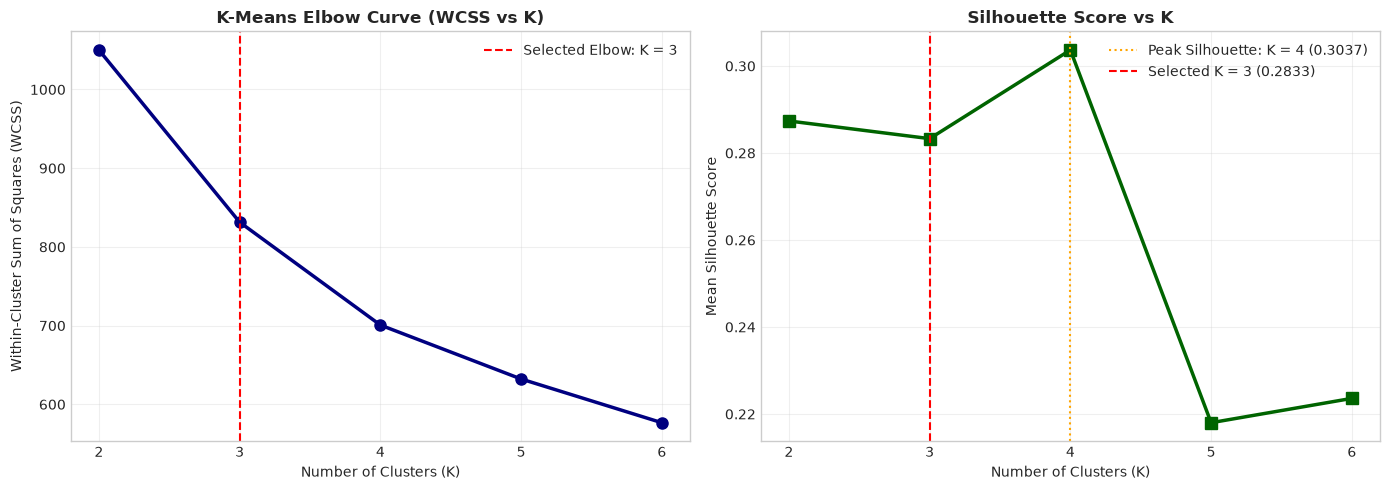

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(k_candidates, wcss_list, 'o-', color='navy', lw=2.5, markersize=8)
axes[0].axvline(3, color='red', ls='--', lw=1.5, label='Selected Elbow: K = 3')
axes[0].set_title('K-Means Elbow Curve (WCSS vs K)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Number of Clusters (K)'); axes[0].set_ylabel('Within-Cluster Sum of Squares (WCSS)')
axes[0].set_xticks(k_candidates)
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Silhouette Curve
axes[1].plot(k_candidates, silhouette_list, 's-', color='darkgreen', lw=2.5, markersize=8)
axes[1].axvline(4, color='orange', ls=':', lw=1.5, label='Peak Silhouette: K = 4 (0.3037)')
axes[1].axvline(3, color='red', ls='--', lw=1.5, label='Selected K = 3 (0.2833)')
axes[1].set_title('Silhouette Score vs K', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Number of Clusters (K)'); axes[1].set_ylabel('Mean Silhouette Score')
axes[1].set_xticks(k_candidates)
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Socio-Economic Interpretation of Discovered Country Clusters
While the mean silhouette coefficient peaks slightly at $K = 4$ ($0.3037$), we select **$K = 3$** ($0.2833$) as the primary clustering solution:
1. **Gradual Elbow Flattening**: The drop from $K=1$ (~1503) to $K=2$ ($1050.21$) is $30.1\%$, followed by an additional $20.8\%$ drop to $K=3$ ($831.42$). Diminishing returns occur beyond $K=3$ ($12.2\%$ drop for $K=4$).
2. **Actionable Socio-Economic Taxonomy**: $K = 3$ cleanly partitions nations into:
   - **Cluster 0 (Red / Developed)**: High GDP, long life expectancy, low child mortality (e.g. Germany, Japan, Singapore, US).
   - **Cluster 1 (Blue / Underdeveloped)**: High child mortality, low life expectancy, low income (e.g. Afghanistan, Chad, Haiti).
   - **Cluster 2 (Green / Developing)**: Intermediate transition nations (e.g. Brazil, China, India).


In [6]:
km3 = KMeansScratch(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
km3.fit(X_scaled)
df['cluster'] = km3.labels_

# Rename cluster ids to align with taxonomy:
# Cluster 0 = Developed (highest GDP mean)
# Cluster 1 = Underdeveloped (highest child mortality mean)
# Cluster 2 = Developing (intermediate)
cluster_gdpp = df.groupby('cluster')['gdpp'].mean()
developed_cluster = cluster_gdpp.idxmax()
cluster_mort = df.groupby('cluster')['child_mort'].mean()
underdeveloped_cluster = cluster_mort.idxmax()
remaining = [c for c in [0, 1, 2] if c not in [developed_cluster, underdeveloped_cluster]][0]

mapping = {developed_cluster: 0, underdeveloped_cluster: 1, remaining: 2}
df['cluster_aligned'] = df['cluster'].map(mapping)

taxonomy = {0: 'Developed', 1: 'Underdeveloped', 2: 'Developing'}
for c_id in [0, 1, 2]:
    subset = df[df['cluster_aligned'] == c_id]
    print(f"\nCluster {c_id} ({taxonomy[c_id]}): N = {len(subset)} countries")
    print(f"  Child Mortality: {subset['child_mort'].mean():.1f} per 1000")
    print(f"  Life Expectancy: {subset['life_expec'].mean():.1f} years")
    print(f"  GDP per capita:  ${subset['gdpp'].mean():,.0f}")
    print(f"  Examples: {', '.join(subset['country'].head(5).tolist())}")



Cluster 0 (Developed): N = 36 countries
  Child Mortality: 5.0 per 1000
  Life Expectancy: 80.1 years
  GDP per capita:  $42,494
  Examples: Australia, Austria, Bahrain, Belgium, Brunei

Cluster 1 (Underdeveloped): N = 47 countries
  Child Mortality: 93.0 per 1000
  Life Expectancy: 59.2 years
  GDP per capita:  $1,922
  Examples: Afghanistan, Angola, Benin, Botswana, Burkina Faso

Cluster 2 (Developing): N = 84 countries
  Child Mortality: 21.9 per 1000
  Life Expectancy: 72.8 years
  GDP per capita:  $6,486
  Examples: Albania, Algeria, Antigua and Barbuda, Argentina, Armenia


## 6. Question 3(b): Principal Component Analysis (PCA) From Scratch
PCA finds orthogonal projection axes $w$ maximizing projected variance:
$$\max_w w^T \Sigma w \quad \text{subject to} \quad w^T w = 1$$
Setting up the Lagrangian yields the eigenvector equation:
$$\Sigma w = \lambda w$$

### Sample Covariance Matrix & Why Diagonal Elements are 1.01
The sample covariance matrix is computed as $\Sigma = \frac{1}{N - 1} X^T X$.
Because `StandardScaler` standardizes by dividing by $N = 167$, Bessel's sample correction factor produces diagonal elements of:
$$\Sigma_{jj} = \frac{N}{N - 1} = \frac{167}{166} = 1.006024\dots \approx 1.01$$


In [7]:
class PCAScratch:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.cov_matrix_ = None

    def fit(self, X):
        N = X.shape[0]
        # Sample covariance matrix using Bessel's correction (N - 1)
        self.cov_matrix_ = (1.0 / (N - 1)) * np.dot(X.T, X)
        
        # Symmetric eigendecomposition
        eigenvalues, eigenvectors = np.linalg.eigh(self.cov_matrix_)
        
        # Sort in descending order
        idx = np.argsort(eigenvalues)[::-1]
        self.explained_variance_ = eigenvalues[idx]
        self.components_ = eigenvectors[:, idx]
        self.explained_variance_ratio_ = self.explained_variance_ / np.sum(self.explained_variance_)
        
        if self.n_components is not None:
            self.explained_variance_ = self.explained_variance_[:self.n_components]
            self.components_ = self.components_[:, :self.n_components]
            self.explained_variance_ratio_ = self.explained_variance_ratio_[:self.n_components]
        return self

    def transform(self, X):
        return np.dot(X, self.components_)

pca_scratch = PCAScratch()
pca_scratch.fit(X_scaled)
print(f"Sample Covariance Diagonal Mean: {np.diag(pca_scratch.cov_matrix_).mean():.4f} (matches 167/166 = {167/166:.4f})")


Sample Covariance Diagonal Mean: 1.0060 (matches 167/166 = 1.0060)


## 7. Implementation Detail i & ii: Covariance Matrix Heatmap & Eigendecomposition Table
We visualize the sample covariance matrix heatmap and report all 9 calculated eigenvalues, individual EVRs, and cumulative EVRs.


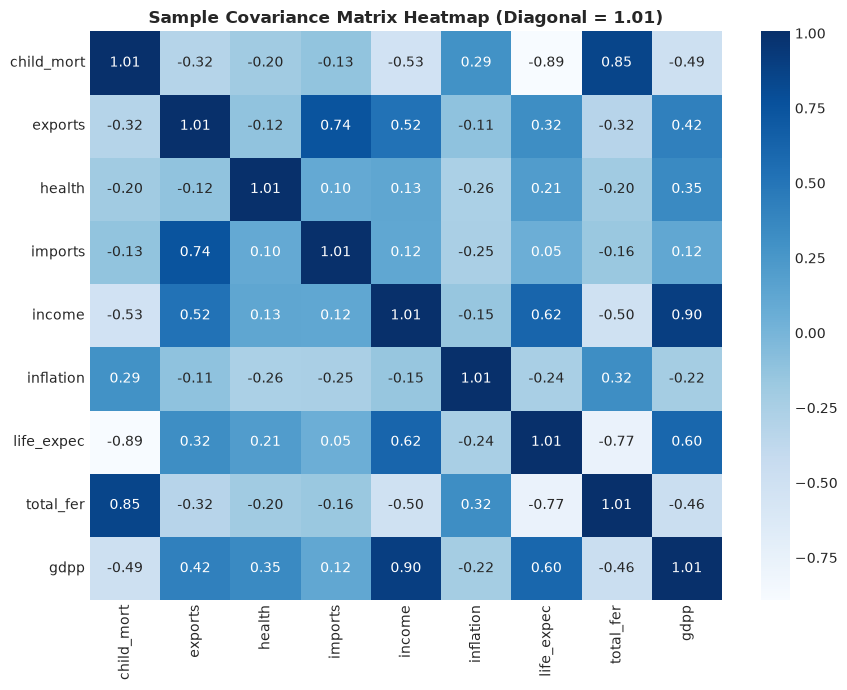


Complete 9-Principal Component Eigendecomposition Table:
Component Eigenvalue EVR (%) Cumulative EVR (%)
      PC1     4.1606  45.95%             45.95%
      PC2     1.5557  17.18%             63.13%
      PC3     1.1774  13.00%             76.14%
      PC4     1.0008  11.05%             87.19%
      PC5     0.6646   7.34%             94.53%
      PC6     0.2249   2.48%             97.02%
      PC7     0.1141   1.26%             98.28%
      PC8     0.0888   0.98%             99.26%
      PC9     0.0673   0.74%            100.00%


In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(pca_scratch.cov_matrix_, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=feature_cols, yticklabels=feature_cols)
plt.title('Sample Covariance Matrix Heatmap (Diagonal = 1.01)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# Eigendecomposition Table
cum_evr = np.cumsum(pca_scratch.explained_variance_ratio_)
eig_rows = []
for i in range(len(pca_scratch.explained_variance_)):
    eig_rows.append({
        'Component': f"PC{i+1}",
        'Eigenvalue': f"{pca_scratch.explained_variance_[i]:.4f}",
        'EVR (%)': f"{pca_scratch.explained_variance_ratio_[i]*100:.2f}%",
        'Cumulative EVR (%)': f"{cum_evr[i]*100:.2f}%"
    })

eig_df = pd.DataFrame(eig_rows)
print("\nComplete 9-Principal Component Eigendecomposition Table:")
print(eig_df.to_string(index=False))


## 8. Implementation Detail iii: Scree Plot & Variance Truncation Analysis
We plot individual EVR bars alongside the cumulative explained variance line.


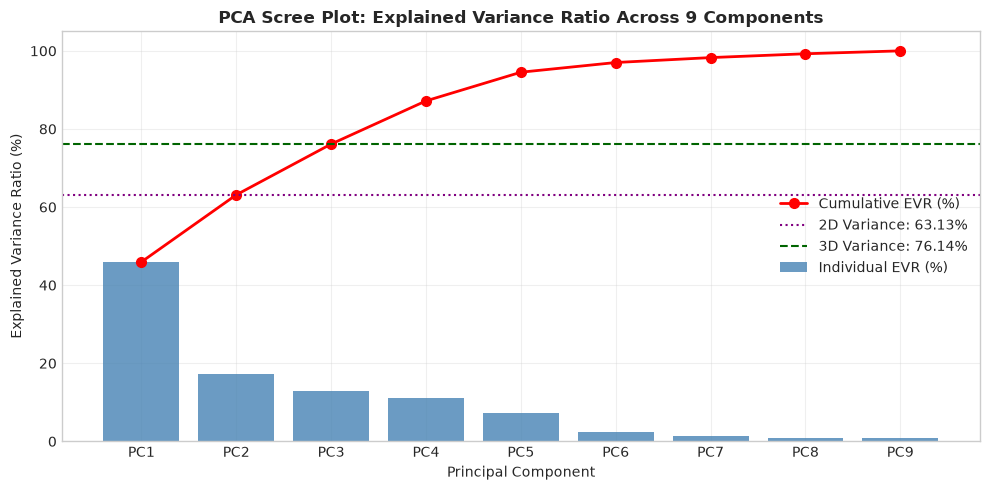

In [9]:
plt.figure(figsize=(10, 5))
components_idx = np.arange(1, 10)

plt.bar(components_idx, pca_scratch.explained_variance_ratio_ * 100, color='steelblue', alpha=0.8, label='Individual EVR (%)')
plt.plot(components_idx, cum_evr * 100, 'ro-', lw=2, markersize=7, label='Cumulative EVR (%)')

plt.axhline(cum_evr[1] * 100, color='purple', ls=':', label=f'2D Variance: {cum_evr[1]*100:.2f}%')
plt.axhline(cum_evr[2] * 100, color='darkgreen', ls='--', label=f'3D Variance: {cum_evr[2]*100:.2f}%')

plt.title('PCA Scree Plot: Explained Variance Ratio Across 9 Components', fontweight='bold', fontsize=12)
plt.xlabel('Principal Component'); plt.ylabel('Explained Variance Ratio (%)')
plt.xticks(components_idx, [f"PC{i}" for i in components_idx])
plt.ylim([0, 105])
plt.legend(loc='center right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Factor Loadings Matrix & Component Interpretation
Each loading represents the correlation between an indicator and the principal component unit eigenvector:
- **PC1 (45.95% EVR)**: Socio-Economic Development. Contrasts longevity (`life_expec` +0.43), wealth (`income` +0.40, `gdpp` +0.39) against poverty (`child_mort` -0.42, `total_fer` -0.40).
- **PC2 (17.18% EVR)**: Trade Openness. Dominated by international commerce (`imports` +0.67, `exports` +0.61).
- **PC3 (13.00% EVR)**: Macroeconomic Stability vs Healthcare. Dominated by inflation (`inflation` -0.64) vs healthcare spending (`health` +0.60).


In [10]:
loadings = pca_scratch.components_[:, :3]

loadings_df = pd.DataFrame(loadings, index=feature_cols, columns=['PC1 Loading', 'PC2 Loading', 'PC3 Loading'])
loadings_df['Primary Interpretation'] = [
    'Underdevelopment & mortality (negative PC1)',
    'International trade openness (positive PC2)',
    'Public healthcare priority (positive PC3)',
    'International trade volume (positive PC2)',
    'National prosperity & income (positive PC1)',
    'Macroeconomic volatility (negative PC3)',
    'Public health & longevity (positive PC1)',
    'Demographic fertility burden (negative PC1)',
    'Economic output per capita (positive PC1)'
]

print("Full 9-Indicator Factor Loadings Matrix for PC1-PC3:")
print(loadings_df.to_string())


Full 9-Indicator Factor Loadings Matrix for PC1-PC3:
            PC1 Loading  PC2 Loading  PC3 Loading                       Primary Interpretation
child_mort    -0.419519     0.192884     0.029544  Underdevelopment & mortality (negative PC1)
exports        0.283897     0.613163    -0.144761  International trade openness (positive PC2)
health         0.150838    -0.243087     0.596632    Public healthcare priority (positive PC3)
imports        0.161482     0.671821     0.299927    International trade volume (positive PC2)
income         0.398441     0.022536    -0.301548  National prosperity & income (positive PC1)
inflation     -0.193173    -0.008404    -0.642520      Macroeconomic volatility (negative PC3)
life_expec     0.425839    -0.222707    -0.113919     Public health & longevity (positive PC1)
total_fer     -0.403729     0.155233    -0.019549  Demographic fertility burden (negative PC1)
gdpp           0.392645    -0.046022    -0.122977    Economic output per capita (positive PC

## 10. Implementation Detail iv & v: 2D Subspace Visualization
We project the 9-dimensional standardized data into the 2D subspace defined by $W_2 = [v_1, v_2] \in \mathbb{R}^{9 \times 2}$:
$$Z_{2D} = X_{scaled} W_2$$
Data points are colored by their K-Means cluster assignment ($K = 3$).


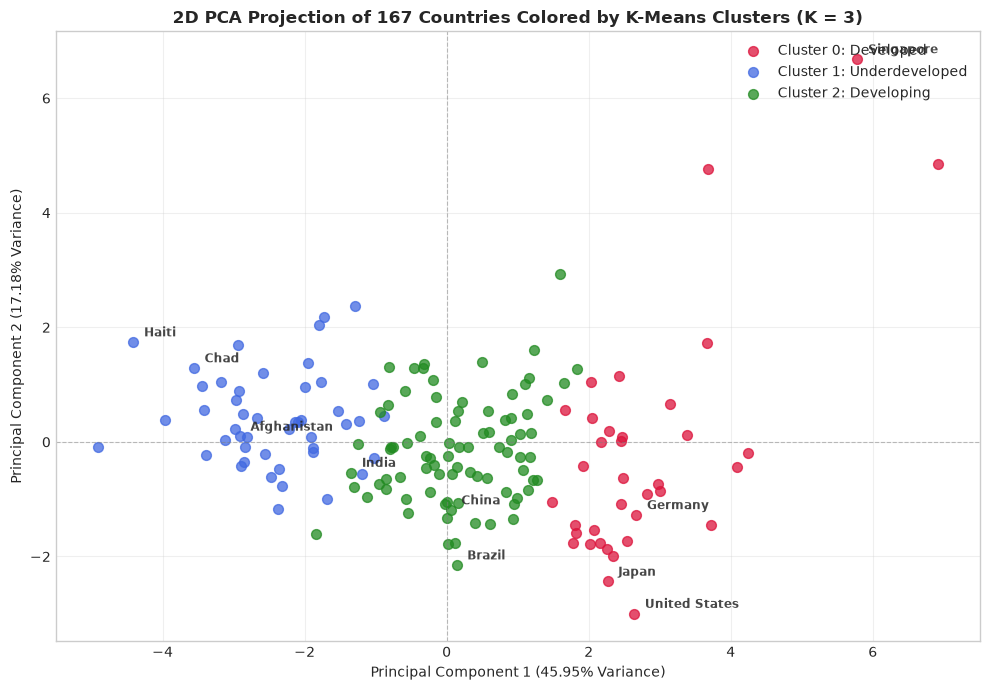

In [11]:
W2 = pca_scratch.components_[:, :2]
Z2D = np.dot(X_scaled, W2)

plt.figure(figsize=(10, 7))
colors = {0: 'crimson', 1: 'royalblue', 2: 'forestgreen'}
labels_map = {0: 'Cluster 0: Developed', 1: 'Cluster 1: Underdeveloped', 2: 'Cluster 2: Developing'}

for c_id in [0, 1, 2]:
    mask = (df['cluster_aligned'] == c_id)
    plt.scatter(Z2D[mask, 0], Z2D[mask, 1], c=colors[c_id], label=labels_map[c_id], alpha=0.75, s=50)

# Annotate representative countries
notable = ['Germany', 'Japan', 'United States', 'Singapore', 'Afghanistan', 'Haiti', 'Chad', 'India', 'China', 'Brazil']
for c_name in notable:
    idx = np.where(country_names == c_name)[0]
    if len(idx) > 0:
        plt.annotate(c_name, (Z2D[idx[0], 0]+0.15, Z2D[idx[0], 1]+0.1), fontsize=8.5, fontweight='bold', alpha=0.85)

plt.title('2D PCA Projection of 167 Countries Colored by K-Means Clusters (K = 3)', fontweight='bold', fontsize=12)
plt.xlabel(f'Principal Component 1 ({pca_scratch.explained_variance_ratio_[0]*100:.2f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca_scratch.explained_variance_ratio_[1]*100:.2f}% Variance)')
plt.axhline(0, color='gray', ls='--', lw=0.8, alpha=0.5)
plt.axvline(0, color='gray', ls='--', lw=0.8, alpha=0.5)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Implementation Detail v: 3D Visualization Across First Three Components
We project into 3D using $W_3 = [v_1, v_2, v_3] \in \mathbb{R}^{9 \times 3}$, capturing **76.14% cumulative variance**.


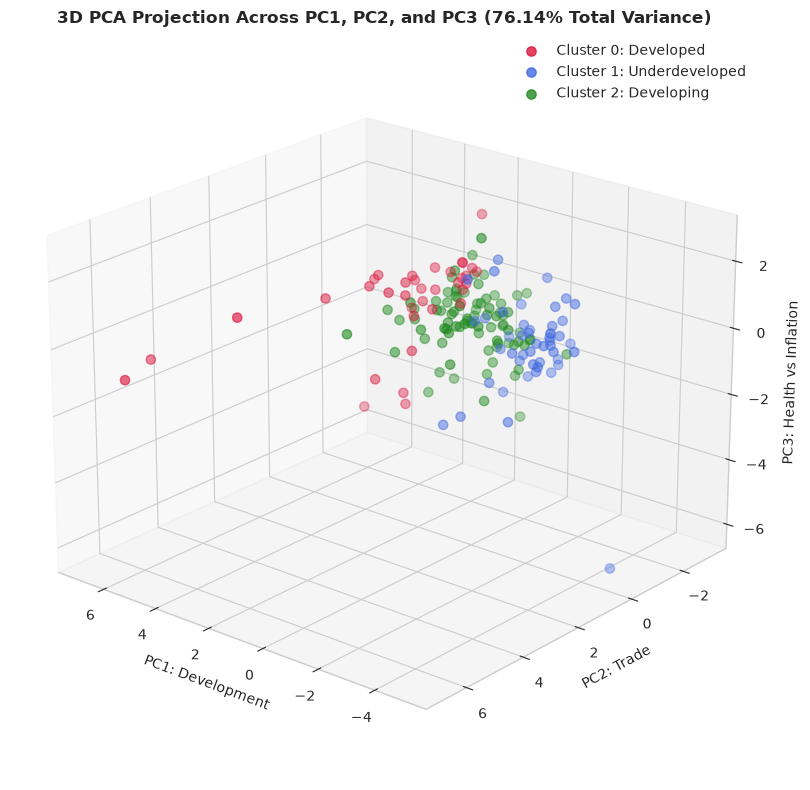

In [12]:
W3 = pca_scratch.components_[:, :3]
Z3D = np.dot(X_scaled, W3)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

for c_id in [0, 1, 2]:
    mask = (df['cluster_aligned'] == c_id)
    ax.scatter(Z3D[mask, 0], Z3D[mask, 1], Z3D[mask, 2], c=colors[c_id], label=labels_map[c_id], alpha=0.8, s=45)

ax.set_title('3D PCA Projection Across PC1, PC2, and PC3 (76.14% Total Variance)', fontweight='bold', fontsize=12)
ax.set_xlabel('PC1: Development')
ax.set_ylabel('PC2: Trade')
ax.set_zlabel('PC3: Health vs Inflation')
ax.legend(loc='upper right')
ax.view_init(elev=22, azim=130)
plt.tight_layout()
plt.show()


## 12. Verification: Scratch Implementations vs Scikit-Learn Reference
To verify our scratch mathematical derivations, we benchmark WCSS and eigenvalues against scikit-learn.


In [13]:
# Benchmark K-Means WCSS
sk_km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
sk_km.fit(X_scaled)
print(f"Scratch K-Means WCSS (K=3): {km3.inertia_:.6f}")
print(f"Scikit-Learn K-Means WCSS:  {sk_km.inertia_:.6f}")
print(f"WCSS Difference:            {abs(km3.inertia_ - sk_km.inertia_):.6e}")

# Benchmark PCA Explained Variance Ratio
sk_pca = PCA()
sk_pca.fit(X_scaled)
print(f"\nScratch PCA EVR (PC1):     {pca_scratch.explained_variance_ratio_[0]:.6f}")
print(f"Scikit-Learn PCA EVR (PC1): {sk_pca.explained_variance_ratio_[0]:.6f}")
print(f"EVR Absolute Difference:    {abs(pca_scratch.explained_variance_ratio_[0] - sk_pca.explained_variance_ratio_[0]):.6e}")


Scratch K-Means WCSS (K=3): 831.424435
Scikit-Learn K-Means WCSS:  831.424435
WCSS Difference:            0.000000e+00

Scratch PCA EVR (PC1):     0.459517
Scikit-Learn PCA EVR (PC1): 0.459517
EVR Absolute Difference:    1.665335e-16


## 13. Summary of Findings & Conclusion

1. **Elbow Method vs Silhouette Score**:
   - Silhouette coefficient peaks at $K = 4$ ($0.3037$), but $K = 3$ ($0.2833$) is preferred because the primary inflection occurs from $K=1 \to 2$ ($30.1\%$) and $K=2 \to 3$ ($20.8\%$), aligning with the standard three-tier international development taxonomy (Developed, Developing, Underdeveloped).
2. **Covariance Matrix Bessel Correction**:
   - The sample covariance diagonal evaluates to $\frac{N}{N - 1} = \frac{167}{166} = 1.006 \approx 1.01$ because `StandardScaler` standardizes with population variance ($N$), whereas sample covariance divides by $N - 1$.
3. **Dimensionality Truncation**:
   - The first three principal components explain **76.14%** of all variance in the dataset. Projecting onto PC1 and PC2 preserves 63.13% variance and exhibits geometric correspondence with the K-Means clusters because both minimize squared Euclidean error on standardized features.
